# RetailPulse — Day 05: Product-Level Demand Forecasting
## AI-Powered Customer Analytics & Demand Forecasting Platform

### Objective
This notebook develops and validates product-level demand forecasting models using monthly sales histories from the Online Retail II dataset.

### Key Methodological Requirements
1. **Chronological Splits:** Held-out test set consisting of the final 3 calendar months. No random shuffling.
2. **Benchmark Baselines:** Naive Forecast (last observed demand) and Rolling 3-Month Average.
3. **Statistical Champion:** Exponential Smoothing (Simple Exponential Smoothing and Holt's Linear Trend).
4. **Metrics:** Weighted Absolute Percentage Error (WAPE), Mean Absolute Error (MAE), and Root Mean Squared Error (RMSE). WAPE is prioritized because product monthly demand series frequently contain zero actuals.
5. **Future Projections:** 3-to-6 month horizon forecasting with 95% uncertainty intervals.

In [1]:
import sys
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Add project root to sys.path
root_dir = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(root_dir))

from src import config
from src.forecasting import (
    prepare_product_series,
    train_test_split_chronological,
    evaluate_product_forecasting,
    generate_future_forecast
)
print("RetailPulse forecasting environment initialized successfully!")

RetailPulse forecasting environment initialized successfully!


## Step 1: Load Monthly Demand & Product Eligibility
We load `data/processed/monthly_product_demand.parquet` and `data/processed/product_summary.parquet` to identify products with sufficient historical activity (at least 18 active months).

In [2]:
df_demand = pd.read_parquet(root_dir / config.MONTHLY_DEMAND_PARQUET)
df_summary = pd.read_parquet(root_dir / config.PRODUCT_SUMMARY_PARQUET)

print(f"Total product-month records: {len(df_demand):,}")
print(f"Total unique products: {len(df_summary):,}")

eligible = df_summary[df_summary["Is_Forecasting_Eligible"]].copy()
print(f"Eligible products (>= 18 active months): {len(eligible):,} ({len(eligible)/len(df_summary)*100:.1f}%)")
display(eligible.head(10))

Total product-month records: 67,058
Total unique products: 4,915
Eligible products (>= 18 active months): 1,839 (37.4%)


,StockCode,Description,Total_Units_Sold,Total_Sales_Revenue,Active_Months,First_Month,Last_Month,Mean_Monthly_Units,Std_Monthly_Units,Is_Forecasting_Eligible
0,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,109898,25197.98,25,2009-12-01,2011-12-01,4395.92,2476.806662,True
1,85099B,JUMBO BAG RED RETROSPOT,98175,183136.14,25,2009-12-01,2011-12-01,3927.00,1389.367122,True
2,21212,PACK OF 72 RETROSPOT CAKE CASES,96472,52948.80,25,2009-12-01,2011-12-01,3858.88,1411.843780,True
3,85123A,WHITE HANGING HEART T-LIGHT HOLDER,96027,262768.47,25,2009-12-01,2011-12-01,3841.08,1575.416795,True
4,22197,SMALL POPCORN HOLDER,89860,80888.34,25,2009-12-01,2011-12-01,3594.40,2817.625862,True
5,84879,ASSORTED COLOUR BIRD ORNAMENT,81590,131817.81,25,2009-12-01,2011-12-01,3263.60,1882.229241,True
6,17003,BROCADE RING PURSE,71394,14948.75,25,2009-12-01,2011-12-01,2855.76,3201.693436,True
7,21977,PACK OF 60 PINK PAISLEY CAKE CASES,56625,28413.63,25,2009-12-01,2011-12-01,2265.00,873.031739,True
8,84991,60 TEATIME FAIRY CAKE CASES,54537,27321.37,25,2009-12-01,2011-12-01,2181.48,996.697552,True
9,15036,ASSORTED COLOURS SILK FAN,44365,33041.55,25,2009-12-01,2011-12-01,1774.60,1417.374157,True


## Step 2: Chronological Train/Test Evaluation on Top Product
We select the top product by total historical volume and evaluate models across the final 3 held-out months.

In [3]:
top_code = eligible.iloc[0]["StockCode"]
top_desc = eligible.iloc[0]["Description"]
print(f"Evaluating top product: {top_code} — {top_desc}")

series = prepare_product_series(df_demand, top_code)
eval_res = evaluate_product_forecasting(series, test_periods=3)

m = eval_res["metrics"]
comp_df = pd.DataFrame([
    {"Model": "Naive Baseline", **m["Naive"]},
    {"Model": "Rolling 3-Month Average", **m["Rolling_3M"]},
    {"Model": "Exponential Smoothing", **m["Exponential_Smoothing"]}
])
print("\n--- Chronological Test Performance ---")
display(comp_df)

Evaluating top product: 84077 — WORLD WAR 2 GLIDERS ASSTD DESIGNS

--- Chronological Test Performance ---


,Model,MAE,RMSE,WAPE_pct,MAPE_pct
0,Naive Baseline,2587.000,2976.553,55.40,78.85
1,Rolling 3-Month Average,2698.889,3122.167,57.79,74.50
2,Exponential Smoothing,2541.082,3019.062,54.41,59.35


## Step 3: Forward Horizon Forecast with Uncertainty Bounds
Forecast 6 months into the future using Exponential Smoothing with 95% confidence bounds.

,Month,Forecast_Units,Lower_CI_95,Upper_CI_95,Model
0,2012-01-01,3607.6,0.0,8713.8,Exponential_Smoothing
1,2012-02-01,3361.8,0.0,8467.9,Exponential_Smoothing
2,2012-03-01,3116.0,0.0,8222.1,Exponential_Smoothing
3,2012-04-01,2870.1,0.0,7976.3,Exponential_Smoothing
4,2012-05-01,2624.3,0.0,7730.5,Exponential_Smoothing
5,2012-06-01,2378.5,0.0,7484.7,Exponential_Smoothing


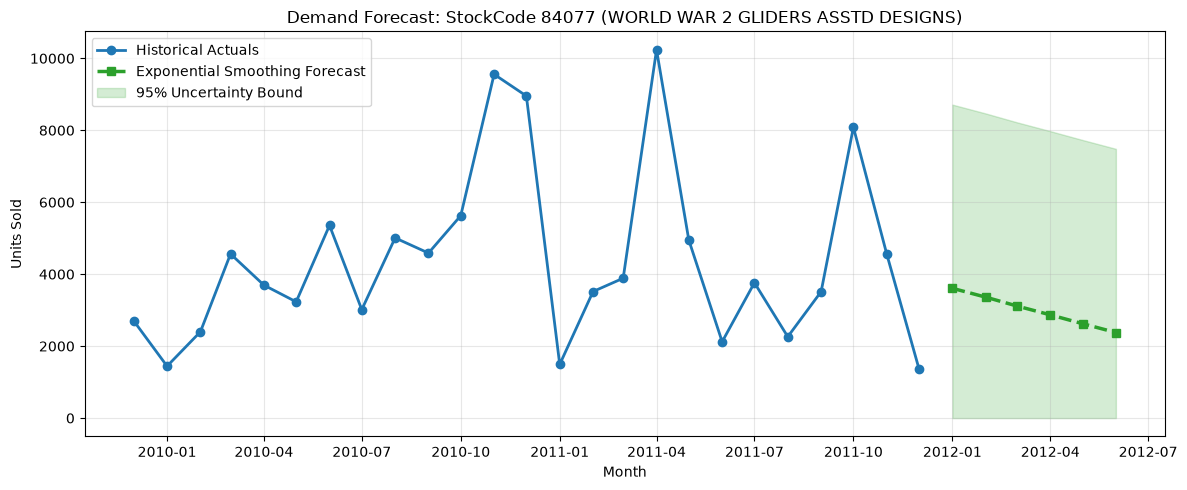

Notebook Day 05 execution completed successfully!


In [4]:
future_df = generate_future_forecast(series, horizon=6, model_type="Exponential_Smoothing")
display(future_df)

# Plot historical actuals and forecast
plt.figure(figsize=(12, 5))
plt.plot(series.index, series.values, marker="o", label="Historical Actuals", color="#1f77b4", linewidth=2)
plt.plot(future_df["Month"], future_df["Forecast_Units"], marker="s", linestyle="--", label="Exponential Smoothing Forecast", color="#2ca02c", linewidth=2.5)
plt.fill_between(future_df["Month"], future_df["Lower_CI_95"], future_df["Upper_CI_95"], color="#2ca02c", alpha=0.2, label="95% Uncertainty Bound")

plt.title(f"Demand Forecast: StockCode {top_code} ({top_desc})")
plt.xlabel("Month")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print("Notebook Day 05 execution completed successfully!")